# 09 — Age, Sex and Own Education: Correlates of Traditional Gender-Role Attitudes

## Purpose

> **Exploratory analysis.** Our main (confirmatory) analysis is the association between parental education and traditional gender-role attitudes in `03_correlations.ipynb`. This notebook is **exploratory**: it looks at three characteristics of the **respondents themselves**. All results are cross-sectional **associations**, based on complete cases and **unweighted** data.

This notebook combines our earlier sex-differences and item-level notebooks into one. Instead of parental education, it focuses on how three respondent characteristics are correlated with traditional gender-role attitudes:

| Variable | WVS item | Coding |
|---|---|---|
| **Age** | Q262 | Age in years (21–91) |
| **Sex** | Q260 → `female` | 0 = male, 1 = female (interviewer-recorded) |
| **Own education** | Q275R | 1 = Lower, 2 = Middle, 3 = Higher |
| **Traditional gender-role attitudes** | composite of Q28–Q31 (`02_scale_reliability.ipynb`) | 1–4, higher = more traditional |

These three variables were the strongest predictors in `07_multivariate_models.ipynb`, and after adjusting for them the parental education coefficients were largely attenuated. Understanding them on their own therefore helps us interpret our main results.

### Hypotheses

**Age**
- **H0c:** Age is not associated with traditional gender-role attitudes.
- **H1c:** Age is associated with traditional gender-role attitudes.

**Sex**
- **H0d:** Men and women do not differ in traditional gender-role attitudes.
- **H1d:** Men and women differ in traditional gender-role attitudes.

**Own education**
- **H0e:** Own education level is not associated with traditional gender-role attitudes.
- **H1e:** Own education level is associated with traditional gender-role attitudes.

All tests are two-tailed. Because we test three hypotheses, we also report a Bonferroni-corrected threshold of .05 / 3 ≈ **.0167**.

## 1. Setup and Data Loading

We use the same packages as in `03_correlations.ipynb`: `scipy` for the correlation tests, `statsmodels` for regression and `matplotlib` for figures.

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools
import matplotlib.pyplot as plt  # figures
from scipy import stats  # Spearman, Mann-Whitney U, Kruskal-Wallis
import statsmodels.formula.api as smf  # OLS regression with formulas
import warnings  # lets us silence routine warnings
warnings.filterwarnings("ignore")  # hide warnings so the output is easier to read

In [2]:
# Identify the root folder of the GitHub repository.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in
if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # cleaned dataset (notebook 04)
OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)  # create the folders if needed
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)  # load the cleaned dataset
outcome = "traditional_gender_attitudes"  # outcome: higher = more traditional (1-4)
print(f"Number of respondents: {df.shape[0]}")  # number of rows

Number of respondents: 2012


## 2. Preparing the Variables

We add readable labels for sex and own education, and group age into six bands for tables and plots. The **tests** use age in years; the bands are only for description.

In [3]:
edu_labels = {1.0: "Lower", 2.0: "Middle", 3.0: "Higher"}  # own education labels
edu_order = ["Lower", "Middle", "Higher"]
df["sex"] = df["female"].map({0.0: "Male", 1.0: "Female"})  # readable sex labels
df["own_education"] = df["Q275R"].map(edu_labels)  # readable own education labels

age_order = ["21-29", "30-39", "40-49", "50-59", "60-69", "70+"]
df["age_group"] = pd.cut(df["Q262"], bins=[20, 29, 39, 49, 59, 69, 120], labels=age_order)  # age bands

variables = ["Q262", "female", "Q275R", outcome]  # the variables used in this notebook
df[variables].isna().sum().to_frame("Missing")  # missing values per variable

,Missing
Q262,0
female,0
Q275R,4
traditional_gender_attitudes,42


Age and sex have no missing values. Own education is missing for 4 respondents and the gender-role score for 42 respondents (those who did not answer enough of Q28–Q31). Each test below uses all respondents with valid values on the variables involved (complete cases).

In [4]:
predictor_desc = pd.DataFrame({
    "Age (years)": df["Q262"].describe()[["count", "mean", "std", "min", "50%", "max"]].values,
}, index=["N", "Mean", "SD", "Min", "Median", "Max"]).T  # age summary

sex_counts = df["sex"].value_counts().reindex(["Male", "Female"])  # sex distribution
edu_counts = df["own_education"].value_counts().reindex(edu_order)  # own education distribution
dist = pd.concat([
    pd.DataFrame({"Variable": "Sex", "Category": sex_counts.index, "N": sex_counts.values}),
    pd.DataFrame({"Variable": "Own education", "Category": edu_counts.index, "N": edu_counts.values}),
])
dist["Percent"] = dist.groupby("Variable")["N"].transform(lambda n: 100 * n / n.sum())  # % within each variable

dist.to_csv(OUTPUT_TABLES / "demographics_distribution.csv", index=False)  # save the table
display(predictor_desc.round(2))
dist.round(1)

,N,Mean,SD,Min,Median,Max
Age (years),2012.0,47.78,16.23,21.0,47.0,91.0


,Variable,Category,N,Percent
0,Sex,Male,924,45.9
1,Sex,Female,1088,54.1
0,Own education,Lower,373,18.6
1,Own education,Middle,613,30.5
2,Own education,Higher,1022,50.9


### Interpretation

Respondents are aged **21 to 91** (mean ≈ 47.8, SD ≈ 16.2). There are slightly more women (**54%**) than men (**46%**). Just over half of the respondents (**51%**) have higher education, about 31% middle and 19% lower education, so the sample is fairly highly educated.

## 3. Age and Gender-Role Attitudes (H1c)

### 3.1 Descriptive pattern by age group

In [5]:
age_desc = (df.dropna(subset=[outcome]).groupby("age_group", observed=True)[outcome]
            .agg(N="count", Mean="mean", SD="std", Median="median").reindex(age_order))  # one row per age band
age_desc.to_csv(OUTPUT_TABLES / "demographics_age_group_descriptives.csv")  # save the table
age_desc.round(3)

,N,Mean,SD,Median
age_group,,,,
21-29,327,1.852,0.562,2.00
30-39,358,1.998,0.571,2.00
40-49,379,2.111,0.567,2.00
50-59,377,2.186,0.521,2.00
60-69,327,2.285,0.481,2.25
70+,202,2.368,0.436,2.25


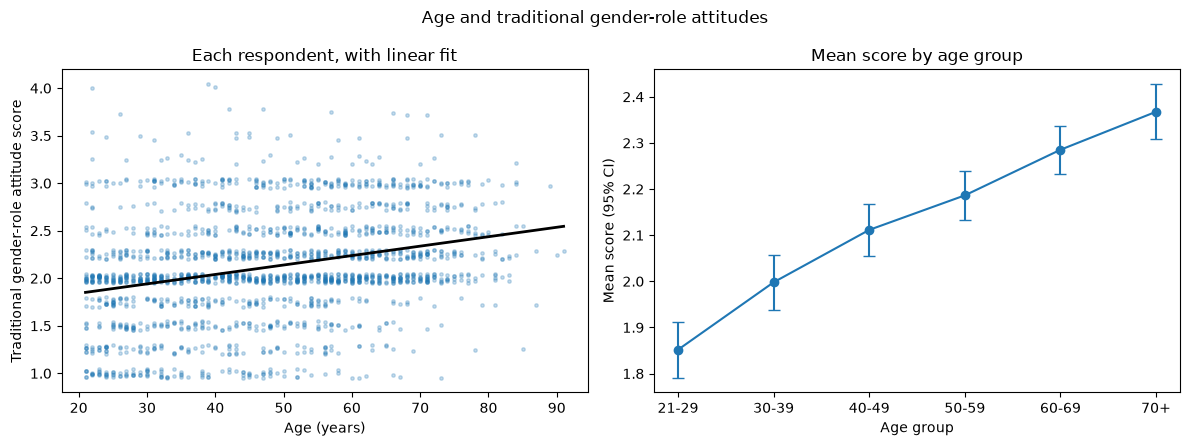

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: every respondent (with a little vertical jitter so overlapping points are visible).
d = df[["Q262", outcome]].dropna()
rng = np.random.default_rng(4002)  # fixed seed so the figure is reproducible
axes[0].scatter(d["Q262"], d[outcome] + rng.uniform(-0.05, 0.05, len(d)), s=6, alpha=0.25)
slope, intercept = np.polyfit(d["Q262"], d[outcome], 1)  # straight-line fit for reference
xs = np.array([d["Q262"].min(), d["Q262"].max()])
axes[0].plot(xs, intercept + slope * xs, color="black", linewidth=2)
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Traditional gender-role attitude score")
axes[0].set_title("Each respondent, with linear fit")

# Right: mean and 95% confidence interval per age band.
se = age_desc["SD"] / np.sqrt(age_desc["N"])
axes[1].errorbar(range(len(age_desc)), age_desc["Mean"], yerr=1.96 * se, fmt="o-", capsize=4)
axes[1].set_xticks(range(len(age_desc)), age_desc.index)
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Mean score (95% CI)")
axes[1].set_title("Mean score by age group")

fig.suptitle("Age and traditional gender-role attitudes")
fig.tight_layout()
fig.savefig(OUTPUT_FIGURES / "demographics_age_attitudes.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.2 Spearman correlation

As in `03_correlations.ipynb`, we use **Spearman's rank correlation**, which does not assume a straight-line relationship or normally distributed scores. We also report Pearson's r for comparison.

In [7]:
d = df[["Q262", outcome]].dropna()  # complete cases
rho_age, p_age = stats.spearmanr(d["Q262"], d[outcome])  # Spearman correlation
r_age, p_age_r = stats.pearsonr(d["Q262"], d[outcome])  # Pearson correlation, for comparison
print(f"N = {len(d)}")
print(f"Spearman rho = {rho_age:.3f}, p = {p_age:.2e}")
print(f"Pearson r    = {r_age:.3f}, p = {p_age_r:.2e}")

N = 1970
Spearman rho = 0.307, p = 2.12e-44
Pearson r    = 0.289, p = 3.71e-39


### Interpretation

Age has a **positive, moderate and highly significant** correlation with traditional gender-role attitudes (**ρ = .307**, p < .001, N = 1,970). Older respondents hold more traditional attitudes. The age-group table shows a remarkably steady rise: the mean score goes up in every band, from **1.85** among 21–29-year-olds to **2.37** among those aged 70 and over, a difference of about half a point on the 1–4 scale. Pearson's r (.289) is very similar, so the relationship is close to linear.

We **reject H0c**. Because the data is cross-sectional, we cannot tell whether this is an **ageing** effect (people becoming more traditional as they get older) or a **cohort** effect (older generations grew up with more traditional norms). The cohort explanation seems more plausible given Singapore's rapid social change, but we cannot test it here. Note also that older respondents are much less educated (Section 6), so part of this correlation may reflect education.

## 4. Sex and Gender-Role Attitudes (H1d)

### 4.1 Descriptive comparison

In [8]:
sex_desc = (df.dropna(subset=[outcome]).groupby("sex")[outcome]
            .agg(N="count", Mean="mean", SD="std", Median="median").reindex(["Male", "Female"]))
sex_desc.to_csv(OUTPUT_TABLES / "demographics_sex_descriptives.csv")  # save the table
sex_desc.round(3)

,N,Mean,SD,Median
sex,,,,
Male,905,2.195,0.555,2.0
Female,1065,2.051,0.549,2.0


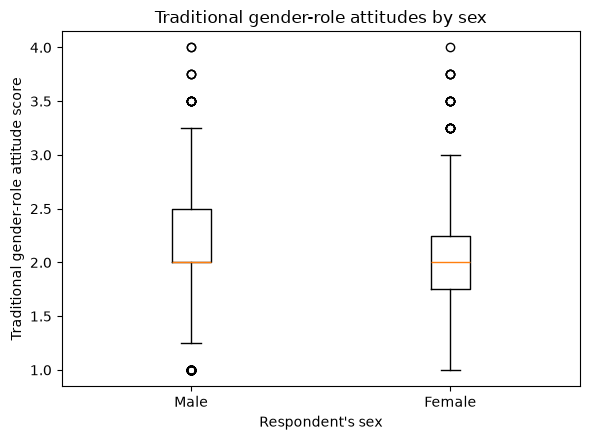

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.boxplot([df.loc[df["sex"] == s, outcome].dropna() for s in ["Male", "Female"]], tick_labels=["Male", "Female"])
ax.set_xlabel("Respondent's sex")
ax.set_ylabel("Traditional gender-role attitude score")
ax.set_title("Traditional gender-role attitudes by sex")
fig.tight_layout()
fig.savefig(OUTPUT_FIGURES / "demographics_sex_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.2 Testing the difference

Sex has only two groups, so we use the **Mann–Whitney U test** (the rank-based test for two groups, which matches our use of Spearman). We also report a **Welch t-test** on the means, and two effect sizes: **Cohen's d** (difference in means in SD units) and the **rank-biserial correlation** (the rank-based effect size that goes with Mann–Whitney). For comparability with the other variables we also give the Spearman correlation between `female` and the score.

In [10]:
men = df.loc[df["female"] == 0, outcome].dropna()
women = df.loc[df["female"] == 1, outcome].dropna()

u_stat, p_u = stats.mannwhitneyu(men, women, alternative="two-sided")  # Mann-Whitney U
t_stat, p_t = stats.ttest_ind(men, women, equal_var=False)  # Welch t-test
pooled_sd = np.sqrt(((len(men) - 1) * men.var() + (len(women) - 1) * women.var()) / (len(men) + len(women) - 2))
cohens_d = (men.mean() - women.mean()) / pooled_sd  # positive = men more traditional
rank_biserial = 2 * u_stat / (len(men) * len(women)) - 1  # positive = men tend to score higher
d = df[["female", outcome]].dropna()
rho_sex, p_sex = stats.spearmanr(d["female"], d[outcome])  # Spearman with female (0/1)

print(f"Mean difference (men - women) = {men.mean() - women.mean():.3f}")
print(f"Mann-Whitney U = {u_stat:.0f}, p = {p_u:.2e}")
print(f"Welch t = {t_stat:.2f}, p = {p_t:.2e}")
print(f"Cohen's d = {cohens_d:.3f}; rank-biserial r = {rank_biserial:.3f}")
print(f"Spearman rho (female, score) = {rho_sex:.3f}, p = {p_sex:.2e}")

Mean difference (men - women) = 0.144
Mann-Whitney U = 553357, p = 7.21e-09
Welch t = 5.75, p = 1.01e-08
Cohen's d = 0.260; rank-biserial r = 0.148
Spearman rho (female, score) = -0.130, p = 6.30e-09


### Interpretation

Women hold **less traditional** gender-role attitudes than men (**M = 2.051** vs. **2.195**, a difference of 0.14 points). The difference is **highly significant** (Mann–Whitney p < .001; Welch t = 5.75, p < .001), so we **reject H0d**.

The effect is **small**: Cohen's d = **0.26** and the rank-biserial correlation = **0.15**, and the Spearman correlation between being female and the score is **ρ = −.130**. The boxplot shows that the two distributions overlap a lot; the medians are the same (2.0), and the difference lies mainly in the upper half of the distribution, where more men hold clearly traditional views. A plausible reason is that traditional gender-role beliefs directly limit women's opportunities, so women have more reason to reject them, but this notebook cannot test why.

## 5. Own Education and Gender-Role Attitudes (H1e)

### 5.1 Descriptive comparison

In [11]:
edu_desc = (df.dropna(subset=[outcome, "Q275R"]).groupby("own_education")[outcome]
            .agg(N="count", Mean="mean", SD="std", Median="median").reindex(edu_order))
edu_desc.to_csv(OUTPUT_TABLES / "demographics_own_education_descriptives.csv")  # save the table
edu_desc.round(3)

,N,Mean,SD,Median
own_education,,,,
Lower,363,2.355,0.479,2.25
Middle,603,2.204,0.534,2.25
Higher,1000,1.978,0.557,2.00


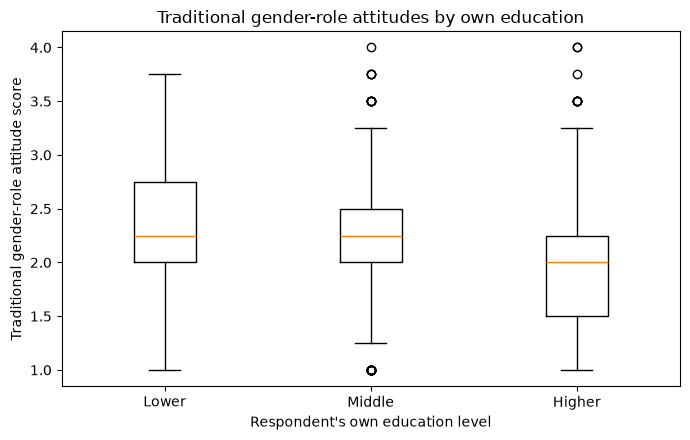

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot([df.loc[df["Q275R"] == k, outcome].dropna() for k in [1, 2, 3]], tick_labels=edu_order)
ax.set_xlabel("Respondent's own education level")
ax.set_ylabel("Traditional gender-role attitude score")
ax.set_title("Traditional gender-role attitudes by own education")
fig.tight_layout()
fig.savefig(OUTPUT_FIGURES / "demographics_own_education_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.2 Spearman correlation and Kruskal–Wallis test

Own education is ordinal with three levels, so we use the same two tests as for parental education in `03_correlations.ipynb`: a **Spearman correlation** (is there a monotonic trend?) and a **Kruskal–Wallis test** (do the three groups differ at all?).

In [13]:
d = df[["Q275R", outcome]].dropna()  # complete cases
rho_edu, p_edu = stats.spearmanr(d["Q275R"], d[outcome])  # Spearman correlation
h_stat, p_kw = stats.kruskal(*[d.loc[d["Q275R"] == k, outcome] for k in [1, 2, 3]])  # Kruskal-Wallis
print(f"N = {len(d)}")
print(f"Spearman rho = {rho_edu:.3f}, p = {p_edu:.2e}")
print(f"Kruskal-Wallis H = {h_stat:.2f} (df = 2), p = {p_kw:.2e}")

N = 1966
Spearman rho = -0.277, p = 5.51e-36
Kruskal-Wallis H = 150.93 (df = 2), p = 1.68e-33


### Interpretation

Own education has a **negative, moderate and highly significant** correlation with traditional attitudes (**ρ = −.277**, p < .001, N = 1,966), and the three groups clearly differ (Kruskal–Wallis H = 150.9, p < .001). Mean scores fall step by step: **2.355** (Lower) → **2.204** (Middle) → **1.978** (Higher). The boxplot shows that the median drops from 2.25 to 2.0 only in the Higher group, so the largest change is between middle and higher education.

We **reject H0e**. More educated respondents hold less traditional gender-role attitudes, which fits the idea that education exposes people to more egalitarian ideas. As with age, this is an association, not proof that education *causes* attitudes to change.

### Summary of the three main tests

In [14]:
main_tests = pd.DataFrame([
    {"Hypothesis": "H1c", "Variable": "Age (years)", "Test": "Spearman", "N": int(df[["Q262", outcome]].dropna().shape[0]), "Statistic": rho_age, "p-value": p_age},
    {"Hypothesis": "H1d", "Variable": "Female (0/1)", "Test": "Spearman (see also Mann-Whitney, 4.2)", "N": int(len(men) + len(women)), "Statistic": rho_sex, "p-value": p_sex},
    {"Hypothesis": "H1e", "Variable": "Own education (1-3)", "Test": "Spearman", "N": int(df[["Q275R", outcome]].dropna().shape[0]), "Statistic": rho_edu, "p-value": p_edu},
])
main_tests["Significant after Bonferroni (p < .0167)"] = np.where(main_tests["p-value"] < 0.05 / 3, "Yes", "No")
main_tests.to_csv(OUTPUT_TABLES / "demographics_main_spearman.csv", index=False)
main_tests.round(4)

,Hypothesis,Variable,Test,N,Statistic,p-value,Significant after Bonferroni (p < .0167)
0,H1c,Age (years),Spearman,1970,0.3075,0.0,Yes
1,H1d,Female (0/1),"Spearman (see also Mann-Whitney, 4.2)",1970,-0.1304,0.0,Yes
2,H1e,Own education (1-3),Spearman,1966,-0.2771,0.0,Yes


All three associations are significant even after the Bonferroni correction. In absolute size, **age** (|ρ| = .31) and **own education** (|ρ| = .28) are more strongly correlated with gender-role attitudes than **sex** (|ρ| = .13). For comparison, mother's and father's education in `03_correlations.ipynb` had correlations of about ρ = −.17.

## 6. How Are Age, Sex and Own Education Related to Each Other?

The three predictors may overlap. If, for example, older respondents are also less educated, then the age and education correlations partly describe the **same** respondents. We therefore look at the full Spearman correlation matrix.

In [15]:
labels = {"Q262": "Age", "female": "Female", "Q275R": "Own education", outcome: "Traditional attitudes"}
d = df[variables].dropna()  # respondents with valid values on all four variables
corr = d.corr(method="spearman").rename(index=labels, columns=labels)  # Spearman matrix
pvals = pd.DataFrame([[stats.spearmanr(d[a], d[b])[1] for b in variables] for a in variables],
                     index=corr.index, columns=corr.columns)  # p-values for each pair
corr.to_csv(OUTPUT_TABLES / "demographics_spearman_matrix.csv")
print(f"N = {len(d)} (complete cases on all four variables)")
display(corr.round(3))
pvals.round(4)

N = 1966 (complete cases on all four variables)


,Age,Female,Own education,Traditional attitudes
Age,1.000,0.021,-0.483,0.308
Female,0.021,1.000,-0.044,-0.131
Own education,-0.483,-0.044,1.000,-0.277
Traditional attitudes,0.308,-0.131,-0.277,1.000


,Age,Female,Own education,Traditional attitudes
Age,0.0000,0.3528,0.0000,0.0
Female,0.3528,0.0000,0.0504,0.0
Own education,0.0000,0.0504,0.0000,0.0
Traditional attitudes,0.0000,0.0000,0.0000,0.0


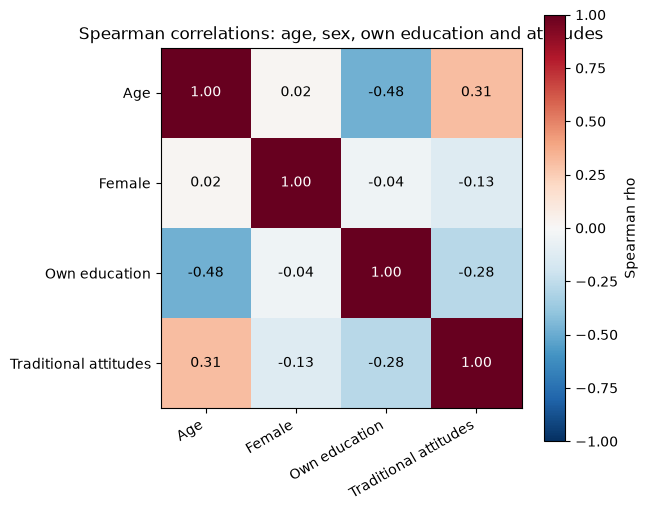

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)  # red = positive, blue = negative
ax.set_xticks(range(4), corr.columns, rotation=30, ha="right")
ax.set_yticks(range(4), corr.index)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.values[i, j]) > 0.5 else "black")
fig.colorbar(im, ax=ax, label="Spearman rho")
ax.set_title("Spearman correlations: age, sex, own education and attitudes")
fig.tight_layout()
fig.savefig(OUTPUT_FIGURES / "demographics_spearman_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation

The key overlap is between **age and own education** (**ρ = −.484**, p < .001): older Singaporeans are much less educated, which reflects the expansion of education over the past decades (see also `07_multivariate_models.ipynb`). Sex is essentially unrelated to age (ρ = .02) and only weakly related to own education.

This means the simple correlations of age (+.31) and education (−.28) with attitudes **overlap**: part of the "age" correlation could be due to older people having less education, and vice versa. Sections 7 and 8 separate these.

## 7. Partial Spearman Correlations

A **partial correlation** shows the association between one variable and attitudes after removing what both have in common with the other two variables. We compute partial Spearman correlations by ranking all variables, regressing both the predictor and the outcome on the other two predictors, and correlating the residuals.

In [17]:
d = df[variables].dropna()  # complete cases
ranks = d.rank()  # Spearman = correlation of ranks
predictors = ["Q262", "female", "Q275R"]

partial_rows = []
for v in predictors:
    others = " + ".join(p for p in predictors if p != v)  # the two variables we control for
    resid_x = smf.ols(f"{v} ~ {others}", data=ranks).fit().resid  # part of v not explained by the others
    resid_y = smf.ols(f"{outcome} ~ {others}", data=ranks).fit().resid  # part of attitudes not explained by the others
    r_partial, p_partial = stats.pearsonr(resid_x, resid_y)  # correlation of the two residuals
    r_zero, _ = stats.spearmanr(d[v], d[outcome])  # simple correlation, same respondents
    partial_rows.append({"Variable": labels[v], "Controlling for": ", ".join(labels[p] for p in predictors if p != v),
                         "N": len(d), "Simple rho": r_zero, "Partial rho": r_partial, "p-value": p_partial})

partial = pd.DataFrame(partial_rows)
partial.to_csv(OUTPUT_TABLES / "demographics_partial_spearman.csv", index=False)
partial.round(4)

,Variable,Controlling for,N,Simple rho,Partial rho,p-value
0,Age,"Female, Own education",1966,0.3077,0.2090,0.0
1,Female,"Age, Own education",1966,-0.1308,-0.1522,0.0
2,Own education,"Age, Female",1966,-0.2771,-0.1616,0.0


### Interpretation

All three variables remain **significantly** associated with attitudes when the other two are held constant (all p < .001):

- **Age:** ρ falls from .307 to **.209**. About a third of the age correlation overlaps with education and sex, but older respondents are still clearly more traditional than younger respondents with the same education.
- **Own education:** ρ falls from −.277 to **−.162**. Education's association is also reduced, mainly because the less educated are older, but a clear association remains.
- **Sex:** ρ actually becomes slightly *stronger*, from −.130 to **−.152**. Women in our sample are slightly *less* educated than men on average, which slightly hides the sex difference in the simple correlation.

So the three characteristics are each **independently** associated with gender-role attitudes.

## 8. Multiple Regression with All Three Variables

To express the associations in the units of the attitude scale, we fit an OLS regression with all three variables together:

**Attitudes = b0 + b1 × Age + b2 × Female + b3 × Own education**

We also report **standardised** coefficients (all variables converted to z-scores), so that the three variables can be compared on the same scale, and check the result with HC3 robust standard errors and with own education entered as categories.

In [18]:
d = df[variables].dropna()  # same respondents for every model
model = smf.ols(f"{outcome} ~ Q262 + female + Q275R", data=d).fit()  # main model
model_hc3 = smf.ols(f"{outcome} ~ Q262 + female + Q275R", data=d).fit(cov_type="HC3")  # robust SEs
z = (d - d.mean()) / d.std()  # z-scores
model_std = smf.ols(f"{outcome} ~ Q262 + female + Q275R", data=z).fit()  # standardised coefficients

reg = pd.DataFrame({
    "b": model.params, "SE": model.bse, "p-value": model.pvalues,
    "95% CI low": model.conf_int()[0], "95% CI high": model.conf_int()[1],
    "Standardised beta": model_std.params, "p-value (HC3)": model_hc3.pvalues,
}).drop("Intercept").rename(index=labels)
reg.to_csv(OUTPUT_TABLES / "demographics_regression.csv")
print(f"N = {int(model.nobs)}, R-squared = {model.rsquared:.4f}, adjusted R-squared = {model.rsquared_adj:.4f}")
reg.round(4)

N = 1966, R-squared = 0.1236, adjusted R-squared = 0.1223


,b,SE,p-value,95% CI low,95% CI high,Standardised beta,p-value (HC3)
Age,0.0071,0.0008,0.0,0.0055,0.0088,0.2069,0.0
Female,-0.1570,0.0236,0.0,-0.2033,-0.1107,-0.1407,0.0
Own education,-0.1236,0.0177,0.0,-0.1583,-0.0889,-0.1704,0.0


In [19]:
model_cat = smf.ols(f"{outcome} ~ Q262 + female + C(Q275R)", data=d).fit()  # own education as categories
pd.DataFrame({"b": model_cat.params, "SE": model_cat.bse, "p-value": model_cat.pvalues}).drop("Intercept").rename(index={
    "C(Q275R)[T.2.0]": "Own education: Middle vs Lower", "C(Q275R)[T.3.0]": "Own education: Higher vs Lower",
    "Q262": "Age", "female": "Female"}).round(4)

,b,SE,p-value
Own education: Middle vs Lower,-0.0559,0.0363,0.1241
Own education: Higher vs Lower,-0.2253,0.0368,0.0000
Age,0.0072,0.0008,0.0000
Female,-0.1580,0.0236,0.0000


### Interpretation

Together, the three variables explain **12.4%** of the variation in gender-role attitudes (R² = .124, N = 1,966). Holding the other two constant:

- **Age:** b = **0.0071** per year (p < .001). Ten years of age go with a score about 0.07 points higher; the difference between a 25- and a 75-year-old is about **0.36 points**.
- **Female:** b = **−0.157** (p < .001). Women score about 0.16 points lower than men of the same age and education.
- **Own education:** b = **−0.124** per level (p < .001). A respondent with higher education scores about 0.25 points lower than one with lower education of the same age and sex.

The standardised betas show that, once they are adjusted for each other, **age (β = .21)** and **own education (β = −.17)** are the strongest correlates, followed closely by **sex (β = −.14)**. All results are unchanged with HC3 robust standard errors.

With own education as categories, the **Higher** group differs clearly from Lower (b = −0.225, p < .001), while the **Middle** group does not differ significantly from Lower after adjustment (b = −0.056, p = .124). So most of the education association comes from **higher** (tertiary-level) education, which matches the boxplot in Section 5.

## 9. Do the Age and Education Associations Differ for Men and Women?

From our earlier sex-differences analysis: we check whether the age and own education correlations are the same for men and women. We first compute the Spearman correlations separately by sex, and then test the differences formally with interaction terms in the regression (as in `06_moderation.ipynb`). We also test whether the education association depends on age.

In [20]:
by_sex_rows = []
for sex in ["Male", "Female"]:
    for v in ["Q262", "Q275R"]:
        dd = df.loc[df["sex"] == sex, [v, outcome]].dropna()
        rho, p = stats.spearmanr(dd[v], dd[outcome])
        by_sex_rows.append({"Sex": sex, "Variable": labels[v], "N": len(dd), "Spearman rho": rho, "p-value": p})
by_sex = pd.DataFrame(by_sex_rows)
by_sex.to_csv(OUTPUT_TABLES / "demographics_spearman_by_sex.csv", index=False)
by_sex.round(4)

,Sex,Variable,N,Spearman rho,p-value
0,Male,Age,905,0.2870,0.0
1,Male,Own education,903,-0.2310,0.0
2,Female,Age,1065,0.3329,0.0
3,Female,Own education,1063,-0.3299,0.0


In [21]:
d = df[variables].dropna()
interaction_rows = []
for term in ["Q262:female", "Q275R:female", "Q262:Q275R"]:  # one interaction per model
    m = smf.ols(f"{outcome} ~ Q262 + female + Q275R + {term}", data=d).fit()
    interaction_rows.append({"Interaction": term.replace("Q262", "Age").replace("Q275R", "Own education").replace("female", "Female").replace(":", " x "),
                             "N": int(m.nobs), "b": m.params[term], "SE": m.bse[term], "p-value": m.pvalues[term]})
interactions = pd.DataFrame(interaction_rows)
interactions["Significant after Bonferroni (p < .0167)"] = np.where(interactions["p-value"] < 0.05 / 3, "Yes", "No")
interactions.to_csv(OUTPUT_TABLES / "demographics_interactions.csv", index=False)
interactions.round(4)

,Interaction,N,b,SE,p-value,Significant after Bonferroni (p < .0167)
0,Age x Female,1966,0.0009,0.0015,0.5335,No
1,Own education x Female,1966,-0.0534,0.0308,0.0836,No
2,Age x Own education,1966,0.0036,0.0011,0.0010,Yes


### Interpretation

**By sex.** Both correlations are significant for men and for women, and both are somewhat **stronger among women**: age ρ = .333 (women) vs. .287 (men); own education ρ = −.330 (women) vs. −.231 (men).

**Formal tests.**
- **Age × Female** (b = 0.0009, p = .53): the age slope does **not** differ significantly between men and women.
- **Own education × Female** (b = −0.053, p = .084): the education slope is steeper for women, but the difference is **not significant** at α = .05. This fits our earlier finding that parental education also seemed slightly more strongly linked to women's attitudes, without reaching significance.
- **Age × Own education** (b = 0.0036, p < .001, significant after Bonferroni): the **positive** interaction means that the negative education slope becomes **weaker** as age increases. In other words, education goes with less traditional attitudes mainly among **younger** respondents; among older respondents, educated and less educated people hold more similar views. This could reflect that younger, highly educated Singaporeans were educated in a more egalitarian environment, but this is an exploratory result.

## 10. Item-Level Correlations: Which Gender-Role Domains?

From our earlier item-level analysis: the composite score averages four statements, and the PCA in `08_pca.ipynb` showed that Q28 (working mothers) behaves somewhat differently from the three "public role" items. We therefore correlate age, sex and own education with **each item separately**. We use the reverse-coded items (`Q28_rev`–`Q31_rev`, 1 = strongly disagree … 4 = strongly agree), so **higher = more traditional**, consistent with the composite score.

| Item | Statement | Domain |
|---|---|---|
| Q28 | When a mother works for pay, the children suffer | Mothers' employment |
| Q29 | On the whole, men make better political leaders than women do | Political leadership |
| Q30 | A university education is more important for a boy than for a girl | Education |
| Q31 | On the whole, men make better business executives than women do | Business leadership |

This gives 4 × 3 = **12 tests**, so we use a Bonferroni threshold of .05 / 12 ≈ **.0042**.

In [22]:
items = {"Q28_rev": "Q28 Working mother: children suffer", "Q29_rev": "Q29 Men better political leaders",
         "Q30_rev": "Q30 University more important for boys", "Q31_rev": "Q31 Men better business executives"}

item_rows = []
for item, iname in items.items():
    for v in predictors:
        dd = df[[v, item]].dropna()
        rho, p = stats.spearmanr(dd[v], dd[item])
        item_rows.append({"Item": iname, "Variable": labels[v], "N": len(dd), "Spearman rho": rho, "p-value": p})
item_corr = pd.DataFrame(item_rows)
item_corr["p < .05/12"] = np.where(item_corr["p-value"] < 0.05 / 12, "Yes", "No")
item_corr.to_csv(OUTPUT_TABLES / "demographics_item_spearman.csv", index=False)
item_corr.pivot(index="Item", columns="Variable", values="Spearman rho")[["Age", "Female", "Own education"]].round(3)

Variable,Age,Female,Own education
Item,,,
Q28 Working mother: children suffer,0.145,-0.045,-0.110
Q29 Men better political leaders,0.232,-0.094,-0.199
Q30 University more important for boys,0.286,-0.113,-0.313
Q31 Men better business executives,0.279,-0.143,-0.232


In [23]:
item_corr.round(4)

,Item,Variable,N,Spearman rho,p-value,p < .05/12
0,Q28 Working mother: children suffer,Age,2004,0.1447,0.000,Yes
1,Q28 Working mother: children suffer,Female,2004,-0.0452,0.043,No
2,Q28 Working mother: children suffer,Own education,2000,-0.1104,0.000,Yes
3,Q29 Men better political leaders,Age,1988,0.2320,0.000,Yes
4,Q29 Men better political leaders,Female,1988,-0.0936,0.000,Yes
5,Q29 Men better political leaders,Own education,1984,-0.1988,0.000,Yes
6,Q30 University more important for boys,Age,2005,0.2862,0.000,Yes
7,Q30 University more important for boys,Female,2005,-0.1133,0.000,Yes
8,Q30 University more important for boys,Own education,2001,-0.3134,0.000,Yes
9,Q31 Men better business executives,Age,1999,0.2789,0.000,Yes


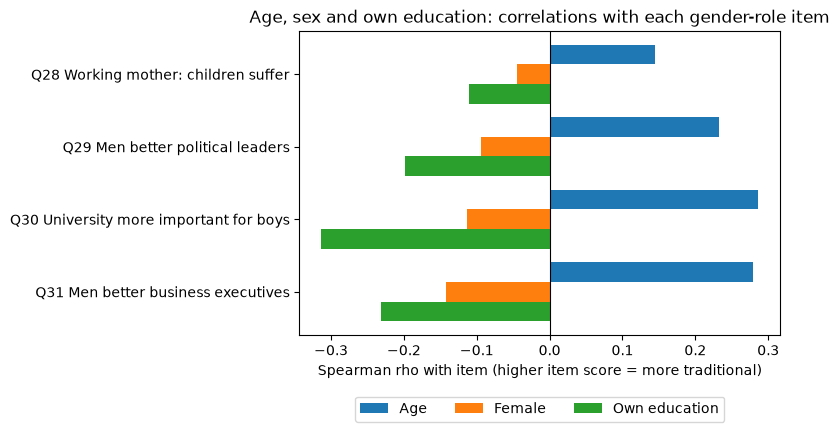

In [24]:
wide = item_corr.pivot(index="Item", columns="Variable", values="Spearman rho")[["Age", "Female", "Own education"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(wide))
for k, col in enumerate(wide.columns):
    ax.barh(x + (k - 1) * 0.27, wide[col], height=0.27, label=col)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(x, wide.index)
ax.invert_yaxis()  # Q28 at the top
ax.set_xlabel("Spearman rho with item (higher item score = more traditional)")
ax.set_title("Age, sex and own education: correlations with each gender-role item")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
fig.tight_layout()
fig.savefig(OUTPUT_FIGURES / "demographics_item_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation

The direction is the same for **all four items**: older respondents, men and less educated respondents are more traditional. **11 of the 12** correlations pass the Bonferroni threshold; the only exception is **sex and Q28** (ρ = −.045, p = .043).

The sizes differ by domain:

- **Q30 (university for boys)** and **Q31 (business executives)** have the strongest associations with age (ρ ≈ .28–.29), and Q30 has the strongest association with own education (**ρ = −.313**).
- **Q28 (working mothers)** has the weakest associations with all three variables (age .145, education −.110, sex −.045). Men and women hardly differ in their views on whether children suffer when a mother works, while they differ more on the public-role items, especially business leadership (Q31, ρ = −.143).

This matches the pattern for parental education in our earlier analyses: attitudes about **women in public roles** are more closely tied to respondents' social characteristics than attitudes about **mothers' employment and childcare**, which seem more widely shared across groups. We did not formally test whether the correlations differ between items, so this pattern is descriptive.

## Summary

*All results in this notebook are exploratory.*

- **Age (H1c supported):** older respondents are more traditional (ρ = .307, p < .001). The mean score rises steadily from 1.85 (aged 21–29) to 2.37 (aged 70+).
- **Sex (H1d supported):** women are less traditional than men (M = 2.05 vs. 2.20; Mann–Whitney p < .001), but the effect is small (d = 0.26, ρ = −.130).
- **Own education (H1e supported):** more educated respondents are less traditional (ρ = −.277, p < .001), mainly because of the **higher** education group.
- All three remain significant after a Bonferroni correction and after **adjusting for each other** (partial ρ: age .209, sex −.152, education −.162). Age and own education overlap strongly (ρ = −.484), so their simple correlations partly describe the same respondents.
- Together they explain about **12%** of the variation in gender-role attitudes. Adjusted for each other, age is the strongest correlate (β = .21), followed by own education (β = −.17) and sex (β = −.14).
- The age and education associations are **not significantly different for men and women** (p = .53 and .084), but the **education association is weaker among older respondents** (age × education p < .001).
- At the **item level**, all 12 correlations point in the same direction. They are strongest for the **public-role** items (especially Q30 and Q31) and weakest for **working mothers (Q28)**, where men and women hardly differ.

**Link to our main research question:** these three variables are clearly more strongly associated with gender-role attitudes than parental education is (|ρ| ≈ .13–.31 vs. ≈ .17). This helps explain why the parental education coefficients were attenuated in `07_multivariate_models.ipynb` once age and own education were added: respondents with more educated parents tend to be younger and more educated themselves. Own education may lie on the pathway between parental education and attitudes, so this does not mean that parental education is unimportant.

**Limitations:**
- The data is cross-sectional, so we cannot separate ageing from cohort effects or establish causal direction.
- Complete-case and **unweighted** analyses.
- Own education is grouped into only three levels and treated as numeric in the correlations and regression (Section 8 checks the categorical version).
- Sex is only measured as male/female by interviewer observation (Q260).
- Several tests were run on the same data; we use Bonferroni corrections where relevant.